# ECG exploratory data analysis

Load an unmodified MIT-BIH Arrhythmia Database signal and its `.atr` annotations. Dataset provenance and license: [DATA_NOTICE.md](../DATA_NOTICE.md). Record 100 is the example used in the starter notebook; set `record_id` to another ID from `data/RECORDS` to inspect it.

Only the **Beat annotations** from the [PhysioNet table](https://physionet.org/static/lightwave/doc/annotations.html) count as annotations in this project: `N L R B A a J S V r F e j n E / f Q ?`. All non-beat markers are ignored as window centers and neighbors. See the [code and data guide](../docs/CODE_GUIDE.md) for function documentation and selection rules.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import wfdb

project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").exists() and (path / "data/RECORDS").exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open the notebook inside the project folder.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from scripts.rules import is_beat_annotation

record_id = "100"
record_ids = (project_root / "data/RECORDS").read_text().splitlines()
if record_id not in record_ids:
    raise ValueError(f"Unknown record ID: {record_id}")
record_path = project_root / "data/raw/mitdb-1.0.0" / record_id
record = wfdb.rdrecord(str(record_path))
annotations = wfdb.rdann(str(record_path), "atr")

if not isinstance(record, wfdb.Record):
    raise TypeError("Expected a single-segment WFDB Record.")

print(f"Record: {record.record_name}")
print(f"Samples: {record.sig_len}, sampling rate: {record.fs} Hz")
print(f"Channels: {list(zip(record.sig_name, record.units))}")
print(f"Raw annotation-file entries: {len(annotations.sample)}")
print(f"Beat annotations: {sum(is_beat_annotation(symbol) for symbol in annotations.symbol)}")

Record: 100
Samples: 650000, sampling rate: 360 Hz
Channels: [('MLII', 'mV'), ('V5', 'mV')]
Raw annotation-file entries: 2274
Beat annotations: 2273


In [2]:
from collections import Counter

Counter(symbol for symbol in annotations.symbol if is_beat_annotation(symbol))

Out[2]: Counter({'N': 2239, 'A': 33, 'V': 1})


## Signal with annotations

The plot uses physical signal values and sample positions from the raw files. Every beat annotation in the selected time interval is marked at its sample position and labeled with its original WFDB symbol. Non-beat markers are omitted; beat symbols are not remapped. The displayed interval is half-open: `[start_s, start_s + duration_s)`.

Select a single channel with `channel=0` or both channels with `channel=(0, 1)`. Set `layout="overlay"` for one shared axis or `layout="stacked"` for separate rows with a shared time axis. Each channel's signal, annotation markers, and symbols share a color. Both examples below use the same 10-second interval.

In [3]:
from scripts.plotting import plot_ecg_with_annotations

### Example 1: both channels on one axis

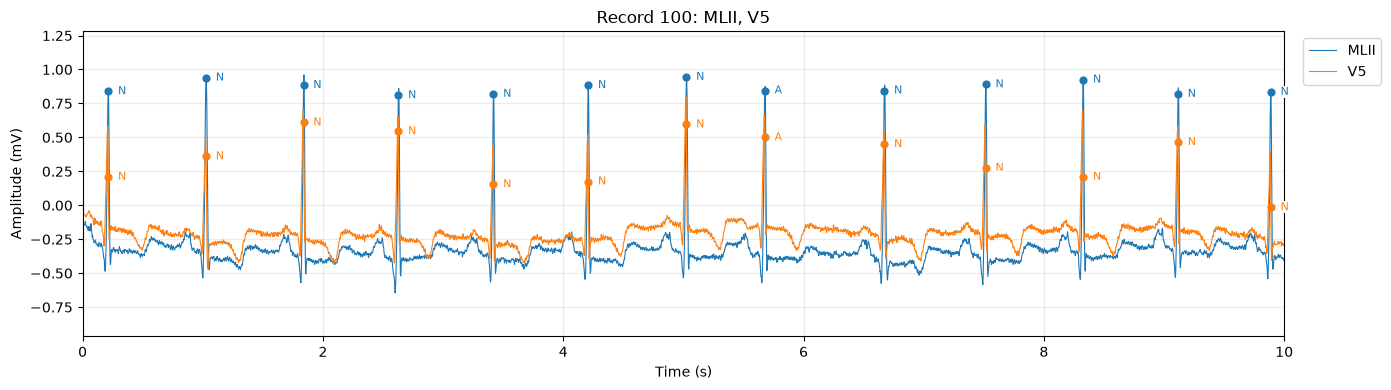

In [4]:
fig, ax = plot_ecg_with_annotations(
    record, annotations, channel=(0, 1), start_s=0, duration_s=10, layout="overlay"
)
plt.show()

### Example 2: one channel per row

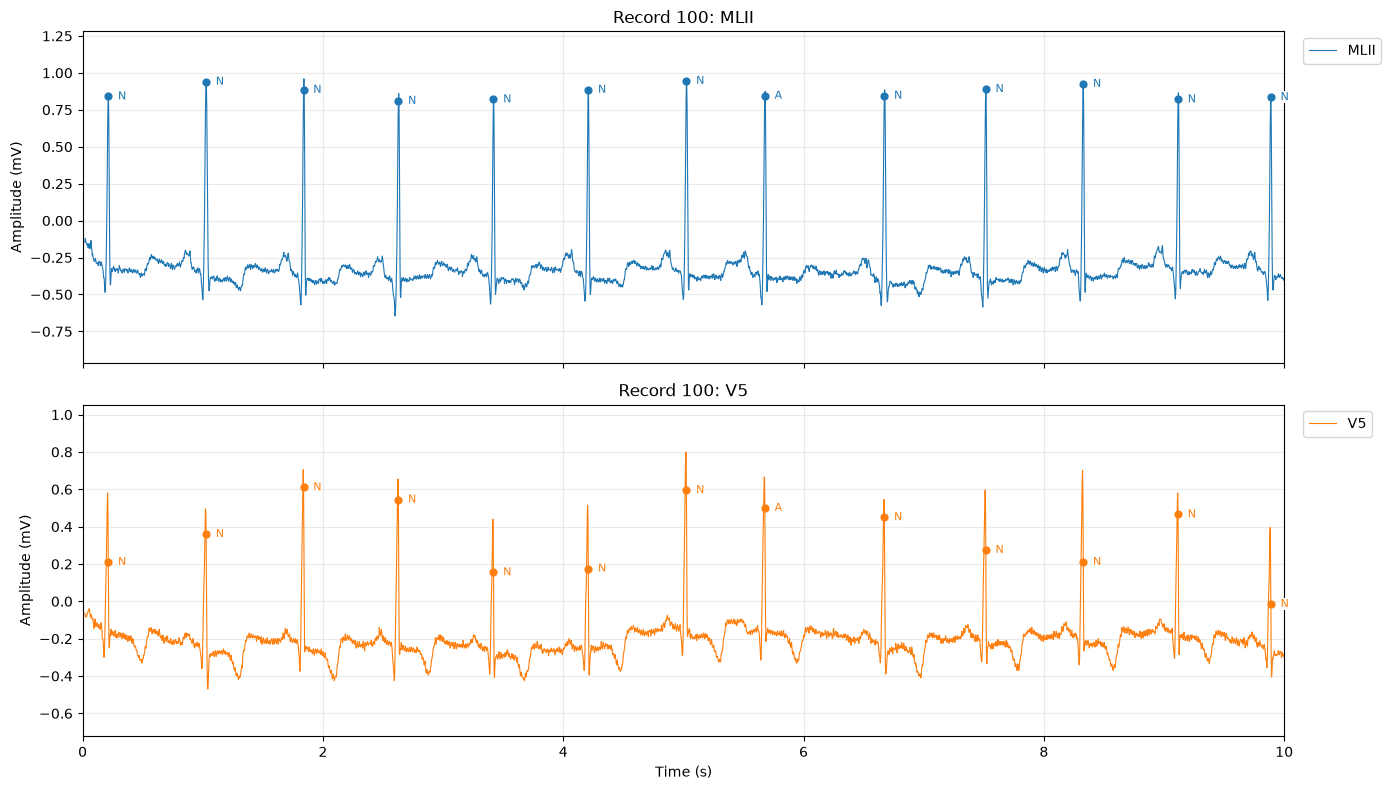

In [5]:
fig, axes = plot_ecg_with_annotations(
    record, annotations, channel=(0, 1), start_s=0, duration_s=10, layout="stacked"
)
plt.show()

## Annotation-centered windows

Each `ECGWindow` contains one selected channel from −0.5 s to +0.5 s, including both endpoints. At 360 Hz this gives 361 samples, with the central annotation at index 180. Missing samples are replaced by zeros; `left_padding` and `right_padding` record their counts, and `is_complete` is false if either count is nonzero.

`annotation` identifies the center. `other_annotations` contains every other **beat annotation** in the interval, including entries with the same symbol and entries at either endpoint. All non-beat markers, including `+`, `~`, `|`, `x`, and `!`, are excluded both as centers and among neighbors. Each retained entry keeps its original annotation index, absolute sample, symbol, auxiliary note, and signed `offset_samples` from the center. Divide the offset by `fs` for seconds.

`extract_ecg_window` selects the center by its index in the annotation set. `generate_ecg_windows` yields windows lazily for an exact symbol (default `N`) and one channel (default `0`). Use full recordings and annotations with the same sample origin.

Extraction can retain zero-padded candidates for inspection and rejection accounting; final datasets below contain complete windows only.

In [6]:
from scripts.windows import ECGWindow, WindowAnnotation

In [7]:
from scripts.windows import extract_ecg_window

In [8]:
from scripts.windows import generate_ecg_windows

In [9]:
windows = list(generate_ecg_windows(record, annotations, channel=0))
print(f"N windows: {len(windows)}")
print(f"Complete: {sum(window.is_complete for window in windows)}")
print(f"Incomplete: {sum(not window.is_complete for window in windows)}")

first_window = windows[0]
print(f"Signal shape: {first_window.signal.shape}; center index: {first_window.center_index}")
print(f"Central annotation: {first_window.annotation}")
print(f"Complete: {first_window.is_complete}; "
      f"padding (left, right): {(first_window.left_padding, first_window.right_padding)}")
print(f"Other annotations present: {first_window.has_other_annotations}")
print(f"Other annotations: {first_window.other_annotations}")

N windows: 2239
Complete: 2237
Incomplete: 2
Signal shape: (361,); center index: 180
Central annotation: WindowAnnotation(annotation_index=1, sample=77, symbol='N', offset_samples=0, aux_note='')
Complete: False; padding (left, right): (103, 0)
Other annotations present: False
Other annotations: ()


## Static window grid

`plot_ecg_windows_grid` plots exactly the list of windows supplied to it as one static Matplotlib figure. Select a manageable subset before calling it; the example below displays the first 20 `N` windows from record 100, channel 0, in four columns.

Time is relative to the central annotation at 0 seconds. All supplied windows share amplitude limits. Red markers identify central annotations; orange markers identify other annotations. Gray regions and `[padded]` titles identify zero padding.

In [10]:
from scripts.plotting import plot_ecg_windows_grid

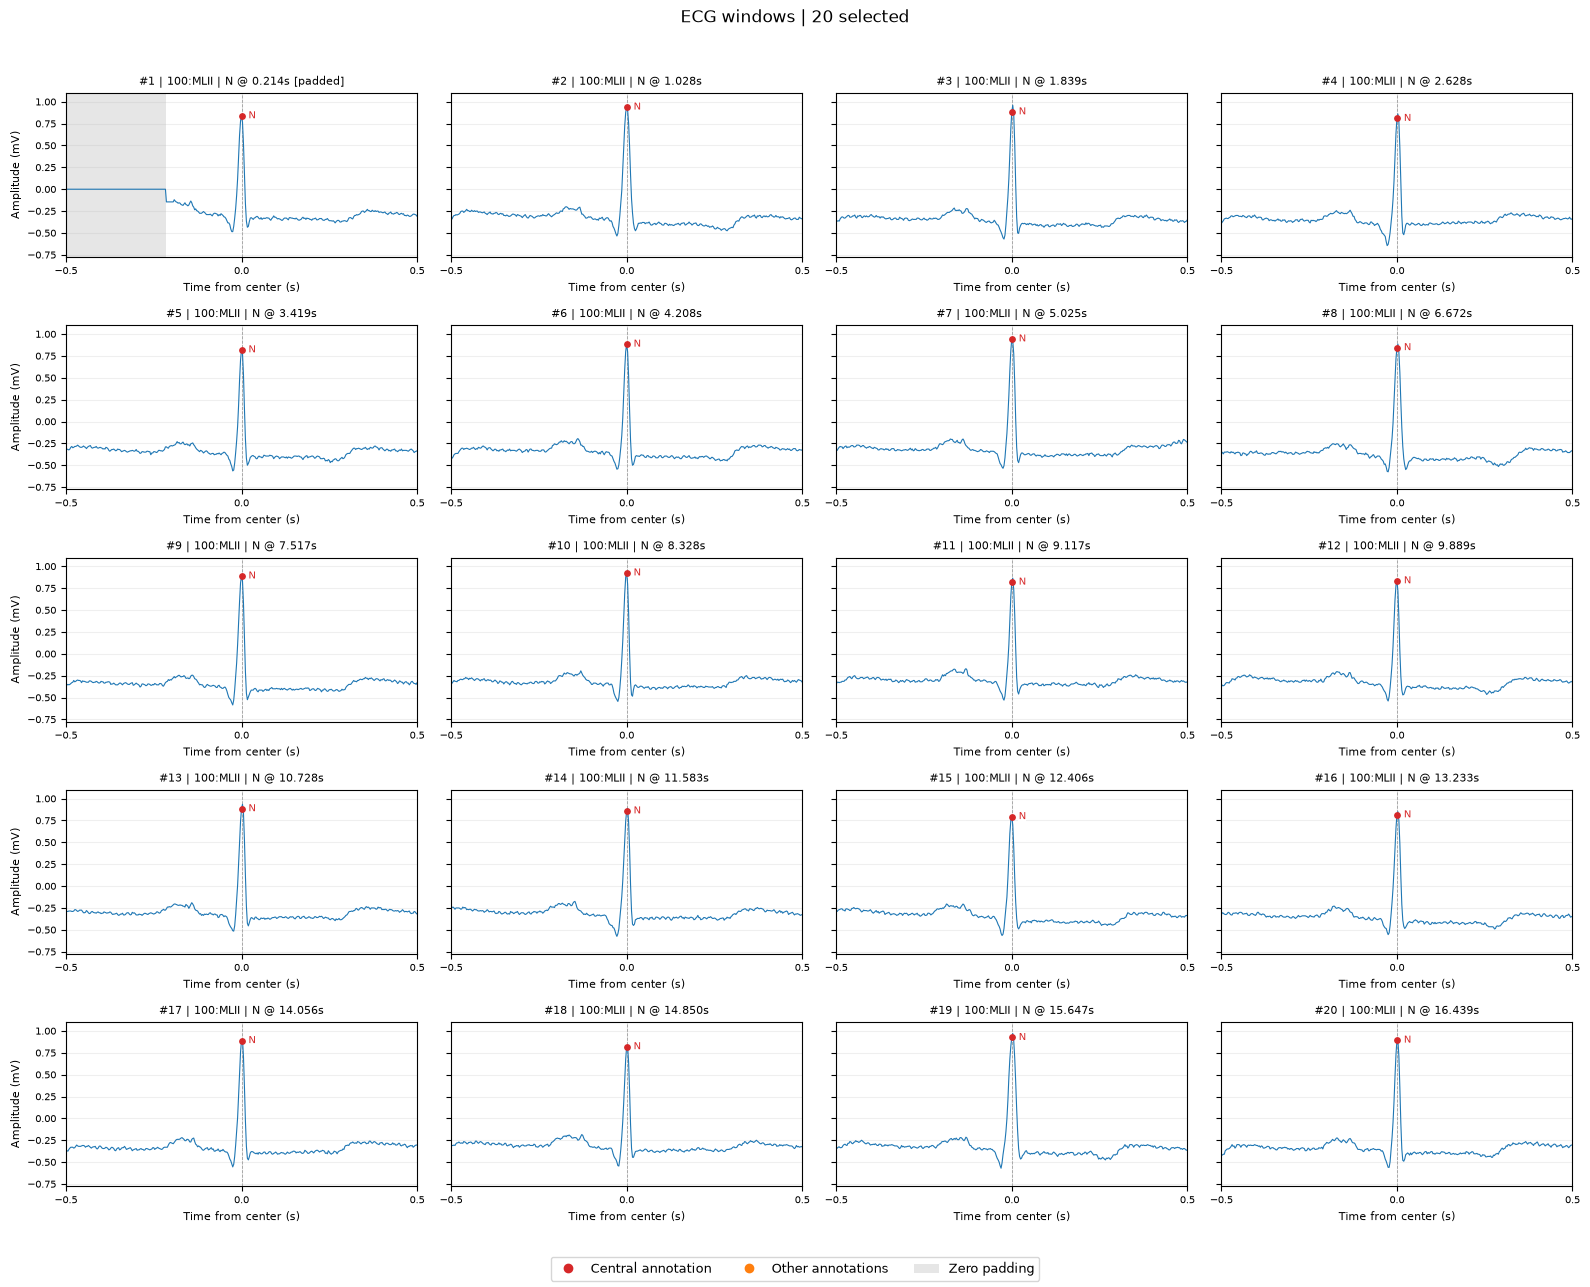

In [11]:
fig, axes = plot_ecg_windows_grid(windows[:20], ncols=4)
plt.show()

## N-window summary across all records

Count all windows centered on `N` annotations from all 48 local records, using channel 0. A **clean** window is complete and has no other retained annotations. All neighboring non-beat entries are ignored. Additional beat annotations, including another `N`, are counted.

**Incomplete** and **With other annotations** are independent counts and may overlap. **Incomplete with other annotations** reports that overlap. Thus total = clean + incomplete + with other annotations − overlap. `window_summary_by_record` retains the counts for each record; the table below shows the totals. The example record and its `windows` list remain available for the plots above.

These are candidate-window counts before the final complete-window selection below.

In [12]:
import pandas as pd
from IPython.display import display

summary_rows = []
for summary_record_id in record_ids:
    summary_path = project_root / "data/raw/mitdb-1.0.0" / summary_record_id
    summary_record = wfdb.rdrecord(str(summary_path))
    summary_annotations = wfdb.rdann(str(summary_path), "atr")
    counts = {
        "Total N windows": 0,
        "Clean (complete, no other annotations)": 0,
        "Incomplete": 0,
        "With other annotations": 0,
        "Incomplete with other annotations": 0,
    }
    for summary_window in generate_ecg_windows(
        summary_record, summary_annotations, annotation_symbol="N", channel=0
    ):
        counts["Total N windows"] += 1
        counts["Clean (complete, no other annotations)"] += int(
            summary_window.is_complete and not summary_window.has_other_annotations
        )
        counts["Incomplete"] += int(not summary_window.is_complete)
        counts["With other annotations"] += int(summary_window.has_other_annotations)
        counts["Incomplete with other annotations"] += int(
            not summary_window.is_complete and summary_window.has_other_annotations
        )
    summary_rows.append({"Record": summary_record_id, **counts})

window_summary_by_record = pd.DataFrame(summary_rows).set_index("Record")
window_summary = window_summary_by_record.sum().rename("Windows").to_frame()
display(window_summary)

,Windows
Total N windows,75052
"Clean (complete, no other annotations)",69656
Incomplete,41
With other annotations,5356
Incomplete with other annotations,1


## Subject split and leakage check

`data/record_splits.csv` assigns all 48 records to **29 training, 9 validation, and 9 test subjects**. Record 100 is fixed in training. `subject_id` is a project grouping key, normally equal to `record_id`; records 201 and 202 both use subject 201. It is not an external patient identifier.

The remaining 46 subject IDs are sorted, permuted with `numpy.random.default_rng(42)`, and assigned 28/9/9 to train/validation/test. All records of a subject inherit the same assignment. Reproduce the CSV with `uv run --locked python scripts/create_splits.py`. The script preserves any differing existing CSV.

The check below validates record coverage, the known 201/202 relationship, subject isolation, counts, and the fixed assignment of record 100. Run the tests with `uv run --locked python -m unittest discover -s tests -v`.

In [13]:
import sys

import pandas as pd
from IPython.display import display

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from scripts.create_splits import validate_record_splits

record_splits = pd.read_csv(project_root / "data/record_splits.csv", dtype=str)
validate_record_splits(record_splits, record_ids)
split_order = ["train", "validation", "test"]
split_sizes = record_splits.groupby("split").agg(
    Subjects=("subject_id", "nunique"), Records=("record_id", "size")
).reindex(split_order)
print("Subject isolation check passed: every subject belongs to exactly one split.")
display(split_sizes)

Subject isolation check passed: every subject belongs to exactly one split.


,Subjects,Records
split,,
train,29,30
validation,9,9
test,9,9


## Window comparison by split and central symbol

Count channel-0 windows for **every original central beat annotation symbol**, without mapping labels. These are candidate-window counts before the final complete-window selection below. All windows inherit the split of their source record. The first table compares split totals, the second compares central symbols, and the last gives quality counts for each symbol in each split. Missing symbol/split combinations are shown as zero.

**Clean** means complete with no other retained annotations. All neighboring non-beat entries are ignored. Other beats, including the same symbol as the center, are counted. **Incomplete** and **With other annotations** may overlap; their intersection is reported separately. For every row, total = clean + incomplete + with other annotations − overlap.

In [14]:
split_count_rows = []
for split_assignment in record_splits.itertuples(index=False):
    split_record_path = project_root / "data/raw/mitdb-1.0.0" / split_assignment.record_id
    split_record = wfdb.rdrecord(str(split_record_path))
    split_annotations = wfdb.rdann(str(split_record_path), "atr")
    for center_symbol in sorted(symbol for symbol in set(split_annotations.symbol) if is_beat_annotation(symbol)):
        split_counts = {
            "Total": 0,
            "Clean": 0,
            "Incomplete": 0,
            "With other annotations": 0,
            "Incomplete with other annotations": 0,
        }
        for split_window in generate_ecg_windows(
            split_record, split_annotations, annotation_symbol=center_symbol, channel=0
        ):
            split_counts["Total"] += 1
            split_counts["Clean"] += int(split_window.is_complete and not split_window.has_other_annotations)
            split_counts["Incomplete"] += int(not split_window.is_complete)
            split_counts["With other annotations"] += int(split_window.has_other_annotations)
            split_counts["Incomplete with other annotations"] += int(
                not split_window.is_complete and split_window.has_other_annotations
            )
        split_count_rows.append({
            "record_id": split_assignment.record_id,
            "subject_id": split_assignment.subject_id,
            "split": split_assignment.split,
            "symbol": center_symbol,
            **split_counts,
        })

window_counts_by_record_and_symbol = pd.DataFrame(split_count_rows)
count_columns = ["Total", "Clean", "Incomplete", "With other annotations", "Incomplete with other annotations"]
all_center_symbols = sorted(window_counts_by_record_and_symbol["symbol"].unique())
comparison_index = pd.MultiIndex.from_product([all_center_symbols, split_order], names=["symbol", "split"])
window_quality_by_symbol_and_split = window_counts_by_record_and_symbol.groupby(
    ["symbol", "split"]
)[count_columns].sum().reindex(comparison_index, fill_value=0)
window_totals_by_split = window_quality_by_symbol_and_split.groupby("split").sum().reindex(split_order)
window_totals_by_symbol_and_split = window_quality_by_symbol_and_split["Total"].unstack("split").reindex(columns=split_order)

display(split_sizes.join(window_totals_by_split))
display(window_totals_by_symbol_and_split)
with pd.option_context("display.max_rows", None):
    display(window_quality_by_symbol_and_split)

,Subjects,Records,Total,Clean,Incomplete,With other annotations,Incomplete with other annotations
split,,,,,,,
train,29,30,68659,61080,33,7548,2
validation,9,9,19298,19037,9,253,1
test,9,9,21537,19148,14,2375,0


split,train,validation,test
symbol,,,
/,2922,2078,2028
A,2388,41,117
E,106,0,0
F,782,3,18
J,81,0,2
L,5583,0,2492
N,45467,13950,15635
Q,31,2,0
R,5434,1825,0


Total  ...  Incomplete with other annotations
symbol split              ...                                   
/      train        2922  ...                                  0
       validation   2078  ...                                  1
       test         2028  ...                                  0
A      train        2388  ...                                  0
       validation     41  ...                                  0
       test          117  ...                                  0
E      train         106  ...                                  0
       validation      0  ...                                  0
       test            0  ...                                  0
F      train         782  ...                                  1
       validation      3  ...                                  0
       test           18  ...                                  0
J      train          81  ...                                  0
       validation      0  ...                                  0
       test            2  ...                                  0
L      train        5583  ...                                  0
       validation      0  ...                                  0
       test         2492  ...                                  0
N      train       45467  ...                                  1
       validation  13950  ...                                  0
       test        15635  ...                                  0
Q      train          31  ...                                  0
       validation      2  ...                                  0
       test            0  ...                                  0
R      train        5434  ...                                  0
       validation   1825  ...                                  0
       test            0  ...                                  0
S      train           2  ...                                  0
       validation      0  ...                                  0
       test            0  ...                                  0
V      train        4548  ...                                  0
       validation   1393  ...                                  0
       test         1189  ...                                  0
a      train         144  ...                                  0
       validation      6  ...                                  0
       test            0  ...                                  0
e      train          16  ...                                  0
       validation      0  ...                                  0
       test            0  ...                                  0
f      train         926  ...                                  0
       validation      0  ...                                  0
       test           56  ...                                  0
j      train         229  ...                                  0
       validation      0  ...                                  0
       test            0  ...                                  0

[45 rows x 5 columns]

## Training statistics and reversible window preprocessing

Fit amplitude statistics using **only complete, clean training N windows from channel 0**. Pool their real samples: overlapping sample occurrences are counted once per window. Reject incomplete windows and windows with additional eligible annotations before fitting. Every fitted window contributes 361 real samples. Real zero amplitudes remain included. The standard deviation uses `ddof=0`. Records without accepted N windows contribute no samples. Validation and test records do not enter this fit.

`preprocess_window(window, training_statistics, mode=...)` returns a new window and a `PreprocessingState`. The modes are `none` (copy unchanged), `center` (`x - training_mean`), and `standardize` (`(x - training_mean) / training_std`). The same training parameters are reused for every window. Each individual window need not have zero mean or unit variance. Median is reported as a descriptive statistic.

Artificial padding stays zero in every mode. Annotation positions, source identifiers, and completeness metadata remain attached. Standardized amplitudes are dimensionless. `inverse_preprocess_window(processed_window, state)` restores physical values and the original unit, up to floating point rounding. The original window is not mutated.

In [15]:
from scripts.create_splits import validate_record_splits
from scripts.datasets import iter_training_n_windows
from scripts.preprocessing import (
    fit_training_statistics,
    inverse_preprocess_window,
    preprocess_window,
)
from scripts.rules import window_rejection_reasons

In [16]:
import pandas as pd
from IPython.display import display

preprocessing_splits = pd.read_csv(project_root / "data/record_splits.csv", dtype=str)
validate_record_splits(preprocessing_splits, record_ids)
training_record_ids = tuple(preprocessing_splits.loc[preprocessing_splits["split"] == "train", "record_id"])
training_statistics = fit_training_statistics(
    iter_training_n_windows(project_root / "data/raw/mitdb-1.0.0", training_record_ids),
    training_record_ids=training_record_ids,
)
training_statistics_table = pd.DataFrame(
    {
        "Value": [training_statistics.mean, training_statistics.median, training_statistics.std],
        "Unit": [training_statistics.unit] * 3,
    },
    index=pd.Index(["Mean", "Median", "Population std (ddof=0)"], name="Statistic"),
)
with pd.option_context("display.precision", 9):
    display(training_statistics_table)
print(f"Training complete, clean N windows: {training_statistics.window_count}")
print(f"Real sample occurrences: {training_statistics.sample_count}")
print(f"Training records contributing accepted N windows: {len(training_statistics.record_ids)} / {len(training_record_ids)}")

Training complete, clean N windows: 41516
Real sample occurrences: 14987276
Training records contributing accepted N windows: 24 / 30


,Value,Unit
Statistic,,
Mean,-0.304524689,mV
Median,-0.275000000,mV
Population std (ddof=0),0.376665248,mV


### Twenty random standardized N windows from record 100

Select 20 distinct complete, clean channel-0 N windows with `numpy.random.default_rng(42)`. Apply the fixed training mean and std, retain the inverse states, and report the maximum inverse error in mV. The grid shows the standardized windows; original physical windows remain available in `random_raw_windows`.

Selected N annotation indices: [1744, 1627, 455, 2210, 1905, 1724, 291, 200, 1471, 1160, 970, 194, 1016, 1937, 212, 1666, 1782, 982, 1575, 1186]
Maximum inverse error: 2.220e-16 mV


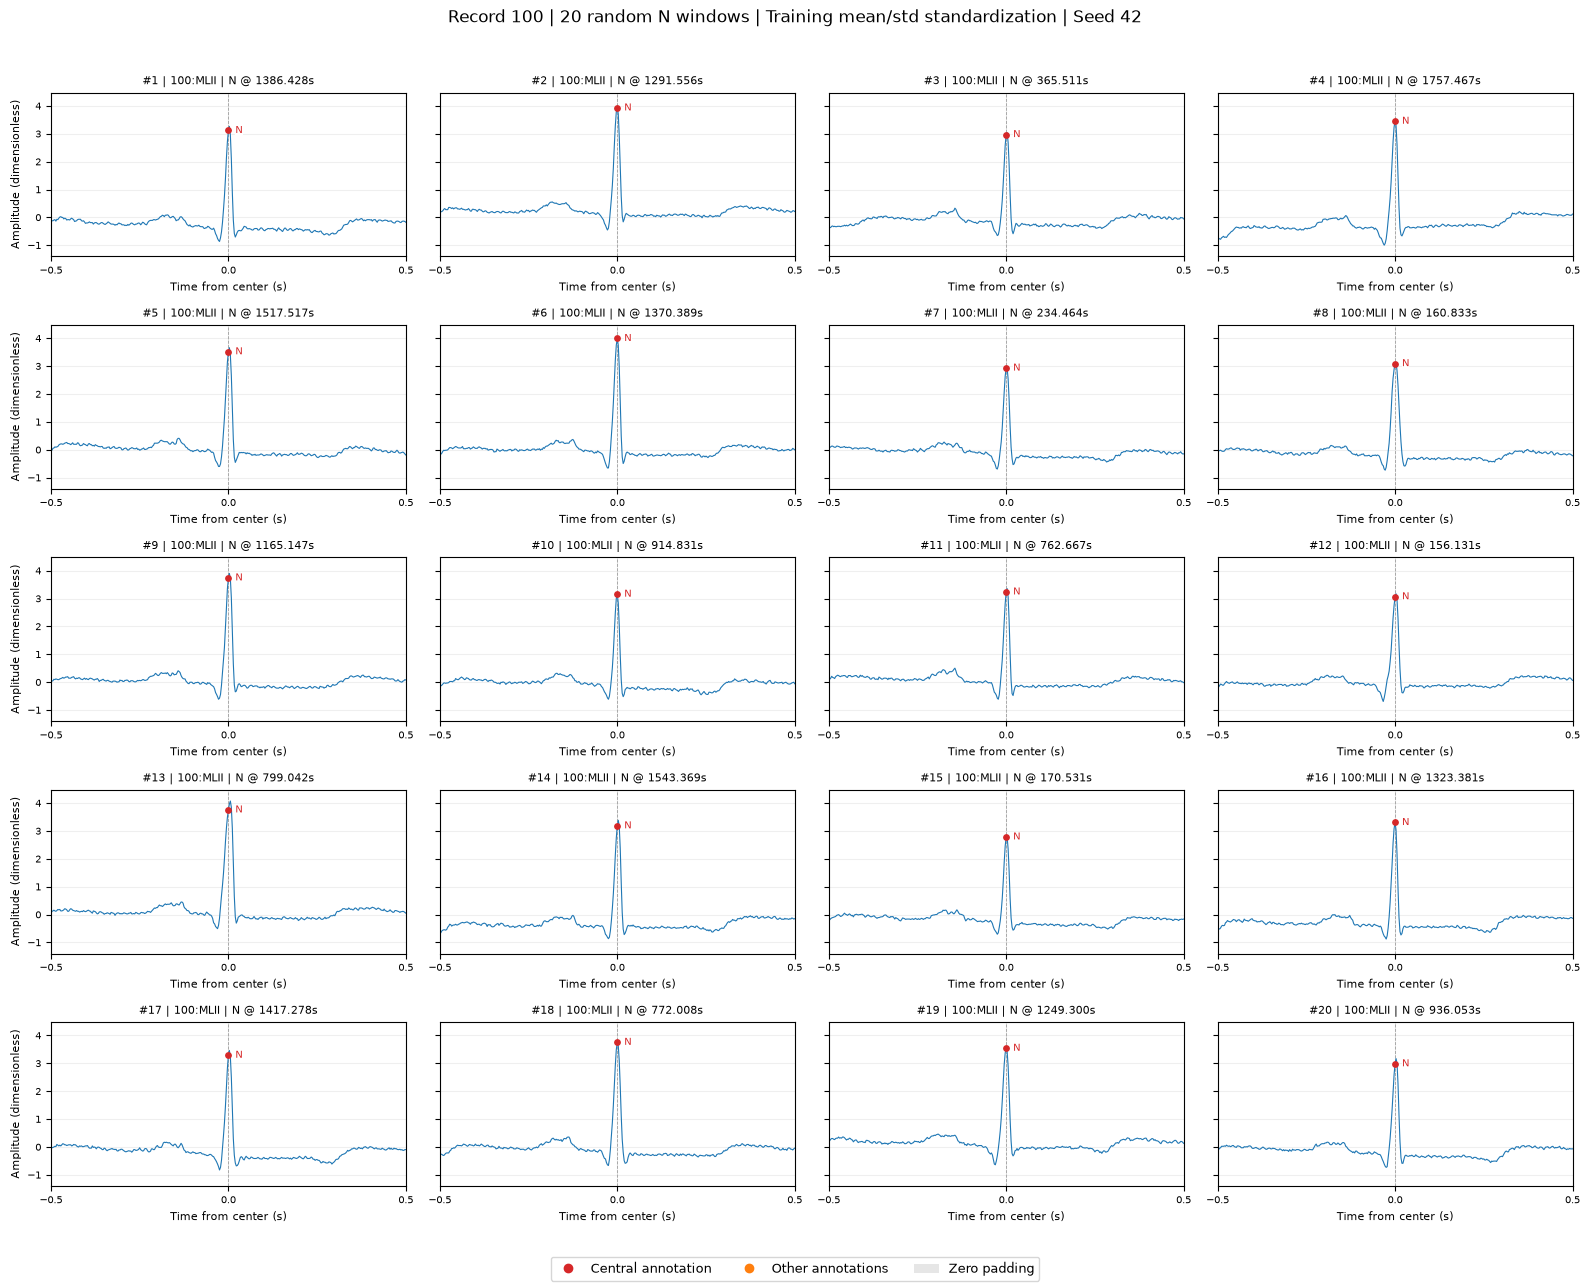

In [17]:
preprocessing_example_record = wfdb.rdrecord(str(project_root / "data/raw/mitdb-1.0.0/100"))
preprocessing_example_annotations = wfdb.rdann(str(project_root / "data/raw/mitdb-1.0.0/100"), "atr")
preprocessing_example_windows = [
    window for window in generate_ecg_windows(
        preprocessing_example_record, preprocessing_example_annotations, annotation_symbol="N", channel=0
    ) if not window_rejection_reasons(window, "train")
]
random_window_indices = np.random.default_rng(42).choice(len(preprocessing_example_windows), size=20, replace=False)
random_raw_windows = [preprocessing_example_windows[index] for index in random_window_indices]
preprocessed_windows_and_states = [
    preprocess_window(window, training_statistics, mode="standardize")
    for window in random_raw_windows
]
random_preprocessed_windows = [window for window, state in preprocessed_windows_and_states]
restored_windows = [inverse_preprocess_window(window, state) for window, state in preprocessed_windows_and_states]
inverse_max_abs_error = max(
    float(np.max(np.abs(restored.signal - original.signal)))
    for original, restored in zip(random_raw_windows, restored_windows)
)
print(f"Selected N annotation indices: {[window.annotation.annotation_index for window in random_raw_windows]}")
print(f"Maximum inverse error: {inverse_max_abs_error:.3e} {training_statistics.unit}")
fig, axes = plot_ecg_windows_grid(random_preprocessed_windows, ncols=4)
fig.suptitle("Record 100 | 20 random N windows | Training mean/std standardization | Seed 42", fontsize=12)
plt.show()

## Final dataset selection and preprocessing audit

Use channel 0 and keep **complete, clean central-N windows in train**. Validation and test accept complete windows with every original central **beat** symbol. All non-beat markers are excluded as centers and ignored among neighbors. Training windows contain no additional eligible annotations; full validation/test windows may contain them. Keep original central symbols in metadata; no binary target mapping is applied.

`dataset_preprocessing_mode` selects `none`, `center`, or `standardize` for all three splits. Reuse the training statistics above, refitted exclusively on the complete, clean central-N windows remaining in train. `prepared_datasets[split].X` has shape `(accepted windows, 361)`; `metadata.iloc[i]` and `states[i]` describe row `X[i]`. Arrays and metadata are held in `prepared_datasets` in memory; rerun the preparation cell to recreate them.

The audit includes every original source entry, including excluded non-beat markers for accounting. These markers never produce windows. `Result shape` describes the accepted subset of each central symbol. If multiple rejection rules apply, their combined reason is reported once; reason counts therefore sum to rejected entries.

In [18]:
from scripts.datasets import prepare_window_datasets

dataset_preprocessing_mode = "standardize"
prepared_datasets, dataset_audit, dataset_rejection_reasons = prepare_window_datasets(
    raw_directory=project_root / "data/raw/mitdb-1.0.0",
    record_splits=preprocessing_splits,
    source_record_ids=record_ids,
    statistics=training_statistics,
    mode=dataset_preprocessing_mode,
)
dataset_summary = dataset_audit.groupby("split")[[
    "Source entries", "Accepted windows", "Rejected entries"
]].sum().reindex(["train", "validation", "test"])
dataset_summary["X shape"] = [prepared_datasets[split].X.shape for split in dataset_summary.index]
display(dataset_summary)
with pd.option_context("display.max_rows", None):
    display(dataset_audit)
    display(dataset_rejection_reasons)

,Source entries,Accepted windows,Rejected entries,X shape
split,,,,
train,71146,41516,29630,"(41516, 361)"
validation,19789,19289,500,"(19289, 361)"
test,21712,21523,189,"(21523, 361)"


Source entries  ...  Result shape
split      symbol                  ...              
train      !                  472  ...      (0, 361)
           "                  431  ...      (0, 361)
           +                  908  ...      (0, 361)
           /                 2922  ...      (0, 361)
           A                 2388  ...      (0, 361)
           E                  106  ...      (0, 361)
           F                  782  ...      (0, 361)
           J                   81  ...      (0, 361)
           L                 5583  ...      (0, 361)
           N                45467  ...  (41516, 361)
           Q                   31  ...      (0, 361)
           R                 5434  ...      (0, 361)
           S                    2  ...      (0, 361)
           V                 4548  ...      (0, 361)
           [                    6  ...      (0, 361)
           ]                    6  ...      (0, 361)
           a                  144  ...      (0, 361)
           e                   16  ...      (0, 361)
           f                  926  ...      (0, 361)
           j                  229  ...      (0, 361)
           x                   60  ...      (0, 361)
           |                  116  ...      (0, 361)
           ~                  488  ...      (0, 361)
validation !                    0  ...      (0, 361)
           "                    4  ...      (0, 361)
           +                  278  ...      (0, 361)
           /                 2078  ...   (2077, 361)
           A                   41  ...     (41, 361)
           E                    0  ...      (0, 361)
           F                    3  ...      (3, 361)
           J                    0  ...      (0, 361)
           L                    0  ...      (0, 361)
           N                13950  ...  (13942, 361)
           Q                    2  ...      (2, 361)
           R                 1825  ...   (1825, 361)
           S                    0  ...      (0, 361)
           V                 1393  ...   (1393, 361)
           [                    0  ...      (0, 361)
           ]                    0  ...      (0, 361)
           a                    6  ...      (6, 361)
           e                    0  ...      (0, 361)
           f                    0  ...      (0, 361)
           j                    0  ...      (0, 361)
           x                  133  ...      (0, 361)
           |                    7  ...      (0, 361)
           ~                   69  ...      (0, 361)
test       !                    0  ...      (0, 361)
           "                    2  ...      (0, 361)
           +                  105  ...      (0, 361)
           /                 2028  ...   (2026, 361)
           A                  117  ...    (117, 361)
           E                    0  ...      (0, 361)
           F                   18  ...     (18, 361)
           J                    2  ...      (2, 361)
           L                 2492  ...   (2490, 361)
           N                15635  ...  (15626, 361)
           Q                    0  ...      (0, 361)
           R                    0  ...      (0, 361)
           S                    0  ...      (0, 361)
           V                 1189  ...   (1188, 361)
           [                    0  ...      (0, 361)
           ]                    0  ...      (0, 361)
           a                    0  ...      (0, 361)
           e                    0  ...      (0, 361)
           f                   56  ...     (56, 361)
           j                    0  ...      (0, 361)
           x                    0  ...      (0, 361)
           |                    9  ...      (0, 361)
           ~                   59  ...      (0, 361)

[69 rows x 4 columns]

,split,symbol,reason,count
0,test,"""",excluded_annotation_symbol,2
1,test,+,excluded_annotation_symbol,105
2,test,/,incomplete_window,2
3,test,L,incomplete_window,2
4,test,N,incomplete_window,9
5,test,V,incomplete_window,1
6,test,|,excluded_annotation_symbol,9
7,test,~,excluded_annotation_symbol,59
8,train,!,excluded_annotation_symbol,472
9,train,"""",excluded_annotation_symbol,431


### Trace one result row back to the source

Choose a split and a zero-based row. Metadata recovers the original record, subject, channel, and central annotation index/sample. Re-read that source window, invert preprocessing with the stored state, and check equality up to floating point rounding. Source interval stop positions are exclusive; the central annotation is at row position 180.

In [19]:
from dataclasses import replace

trace_split = "train"
trace_row_id = 0
trace_dataset = prepared_datasets[trace_split]
trace_metadata = trace_dataset.metadata.iloc[trace_row_id]
trace_source_path = project_root / "data/raw/mitdb-1.0.0" / trace_metadata["record_id"]
trace_source_record = wfdb.rdrecord(str(trace_source_path))
trace_source_annotations = wfdb.rdann(str(trace_source_path), "atr")
trace_source_window = extract_ecg_window(
    trace_source_record, trace_source_annotations,
    annotation_index=int(trace_metadata["annotation_index"]),
    channel=int(trace_metadata["channel"]),
)
trace_processed_window = replace(
    trace_source_window,
    signal=trace_dataset.X[trace_row_id].copy(),
    unit=trace_metadata["unit"],
)
trace_restored_window = inverse_preprocess_window(trace_processed_window, trace_dataset.states[trace_row_id])
np.testing.assert_allclose(trace_restored_window.signal, trace_source_window.signal, rtol=1e-12, atol=1e-12)
display(trace_metadata.to_frame("Value"))
print(f"Dataset row: {trace_split}[{trace_row_id}]")
print(f"Original annotation time: {trace_metadata['annotation_sample'] / trace_metadata['fs']:.6f} s")
print(f"Central annotation position in the row: {trace_source_window.center_index}")
print(f"Maximum source reconstruction error: {np.max(np.abs(trace_restored_window.signal - trace_source_window.signal)):.3e} mV")

Dataset row: train[0]
Original annotation time: 1.027778 s
Central annotation position in the row: 180
Maximum source reconstruction error: 1.665e-16 mV


,Value
row_id,0
record_id,100
subject_id,100
channel,0
channel_name,MLII
annotation_index,2
annotation_sample,370
annotation_symbol,N
fs,360.0
window_start_sample,190
